# Sentinel-2 quality screen: up to 15 scenes per field-month

This notebook reads only the private team_data_full_v1.duckdb. Its raw_v1 and raw_oaf5 schemas contain the individual Sentinel-2 observations. The existing monthly_clearest and monthly_median tables are not inputs.

One method is used throughout: screen every sampled Level-2A scene using local cloud, ten-band completeness, SCL pixels and acquisition conditions; rank qualified scenes; retain up to 15 per field and calendar month. Yield and model performance are never used to rank scenes. We process the official kept, unlocked development fields (folds 1–4), as required by the repository README.

In [1]:
from pathlib import Path
import json, subprocess, sys
import duckdb, pandas as pd, matplotlib.pyplot as plt
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p/"data/team_data_full_v1.duckdb").is_file()), None)
assert ROOT is not None, "Put the private database in data/ and run from the repository."
DB = ROOT/"data/team_data_full_v1.duckdb"
OUT = ROOT/"data/clean"
SCHEMAS = ("raw_v1","raw_oaf5")
con = duckdb.connect(str(DB), read_only=True)
print("Database:",DB.name,"Raw schemas:",SCHEMAS)

Database: team_data_full_v1.duckdb Raw schemas: ('raw_v1', 'raw_oaf5')


## 1. Check every country and year

The full database includes the original Kenya, Malawi and Zimbabwe archive in raw_v1, plus additional countries in raw_oaf5. We inspect every maize country and year. Nigeria has no officially eligible development fields. The official keep, locked and fold columns determine the analysis cohort; they do not contribute to image scores.

In [2]:
inventory = con.execute("""
SELECT l.country_iso3, min(l.season_year) first_year, max(l.season_year) last_year,
       count(*) maize_rows,
       count(*) FILTER(WHERE l.keep AND NOT f.locked AND f.fold BETWEEN 1 AND 4) development_fields
FROM labels l LEFT JOIN folds_all f ON f.release=l.release AND f.field_season_id=l.field_season_id
WHERE l.crop='maize' GROUP BY 1 ORDER BY 1
""").df()
display(inventory)
print("Development fields:",int(inventory.development_fields.sum()))

,country_iso3,first_year,last_year,maize_rows,development_fields
0,BDI,2015,2020,6377,831
1,KEN,2016,2020,24063,15315
2,MWI,2020,2023,3390,2011
3,NGA,2022,2022,115,0
4,RWA,2016,2020,7205,967
5,TZA,2016,2020,7949,1579
6,UGA,2020,2020,246,196
7,ZMB,2018,2020,1870,1035
8,ZWE,2022,2024,7324,3645


Development fields: 25579


## 2. Original image-quality screen

| Factor | Rule |
|---|---|
| Bands | Require sampled Level-2A data, at least one pixel and positive non-null values for B02, B03, B04, B05, B06, B07, B08, B8A, B11, B12. |
| Point SCL | Reject cloud, shadow, cirrus, snow, dark/defective and no-data classes. Review water, unclassified and missing SCL. Vegetation 4 and bare soil 5 are clear. |
| Polygon SCL | At least 80% of sampled 20 m SCL pixels inside the stored footprint must be clear; unknown is reviewed. |
| Cloud and sun | Review local cloud probability at least 60 or sun elevation under 30 degrees. Missing metrics get neutral points. |
| Crop dates | Exclude scenes outside recorded planting and harvest dates; incomplete dates are flagged and allowed. |
| Quality score | 50 points local clear fraction, 25 local cloud, 10 whole-scene cloud, 10 crop timing, 5 sun elevation. |
| Monthly selection | Prefer independent overflights, then fill remaining places with other qualifying scenes, up to 15. Review/reject scenes never fill shortages. |

All additional raw_oaf5 fields are points, so polygon pixel checks apply to the raw_v1 polygon records. A clear point pixel does not prove field purity.

In [3]:
screen={}
for schema in SCHEMAS:
    folder=OUT/f"top15_dev_{schema}"
    if not (folder/"summary.json").is_file():
        subprocess.run([sys.executable,str(ROOT/"notebook/Allen/quality_screen.py"),
                        "--database",str(DB),"--schema",schema,"--output",str(folder),
                        "--window-kind","both","--crop","maize"],cwd=ROOT,check=True)
    info=json.loads((folder/"summary.json").read_text(encoding="utf-8"))
    assert (info["schema"],info["crop"],info["window_kind"],info["top_k"])==(schema,"maize","both",15)
    assert info["cohort"]=="official kept, unlocked development folds 1-4"
    screen[schema]=info
display(pd.DataFrame([{"schema":s,"fields":x["scope_fields"],"candidates":x["candidate_rows"],
"kept":x["decisions"].get("keep",0),"review":x["decisions"].get("review",0),
"rejected":x["decisions"].get("reject",0),"selected":x["selected_scenes"]} for s,x in screen.items()]))

,schema,fields,candidates,kept,review,rejected,selected
0,raw_v1,20971,3344793,2060002,41782,1243009,775944
1,raw_oaf5,4608,780126,402784,17008,360334,152767


In [4]:
paths=[str(OUT/f"top15_dev_{s}/monthly_top15.parquet") for s in SCHEMAS]
display(con.execute("""SELECT country_iso3,count(*) selected_scenes,
count(DISTINCT field_season_id) fields_with_scene,max(quality_rank) largest_rank
FROM read_parquet(?) GROUP BY 1 ORDER BY 1""",[paths]).df())
violations=con.execute("""SELECT count(*) FROM (
SELECT field_season_id,year,month,count(*) n,count(DISTINCT quality_rank) u
FROM read_parquet(?) GROUP BY 1,2,3 HAVING n>15 OR n<>u)""",[paths]).fetchone()[0]
assert violations==0
print("Field-months with >15 scenes or duplicate ranks:",violations)

,country_iso3,selected_scenes,fields_with_scene,largest_rank
0,BDI,4958,804,8
1,KEN,377228,15274,15
2,MWI,82301,2011,15
3,RWA,9505,944,15
4,TZA,65152,1578,15
5,UGA,6890,196,15
6,ZMB,66262,1033,15
7,ZWE,316415,3645,15


Field-months with >15 scenes or duplicate ranks: 0


## 3. Create one model input from the selected scenes

The ranked top-15 table is the primary output. To make a compact input for modeling, the feature script applies the scene offset, takes each band's median among the selected scenes in a month, and averages those monthly features over the field's growing season. This is an aggregation of the selected images, not another selection method. Missing months remain missing. The target and official folds are joined after screening. Impute and scale only within each model training fold.

In [5]:
tables=[]
for schema in SCHEMAS:
    folder=OUT/f"top15_dev_features_{schema}"
    if not (folder/"model_ready.parquet").is_file():
        subprocess.run([sys.executable,str(ROOT/"notebook/Allen/top15_features.py"),
                        "--database",str(DB),"--schema",schema,
                        "--top15",str(OUT/f"top15_dev_{schema}/monthly_top15.parquet"),
                        "--output",str(folder)],cwd=ROOT,check=True)
    info=json.loads((folder/"summary.json").read_text(encoding="utf-8"))
    assert info["selected_scenes"]==screen[schema]["selected_scenes"]
    tables.append(pd.read_parquet(folder/"model_ready.parquet"))
ready=pd.concat(tables,ignore_index=True)
expected=int(inventory.development_fields.sum())
assert len(ready)==expected and ready.field_season_id.is_unique
assert ready.fold.between(1,4).all() and not ready.locked.any()
handoff=OUT/"top15_model_ready.parquet"
ready.to_parquet(handoff,index=False)
print("Saved",handoff,"rows",len(ready))
display(ready.groupby("country_iso3").agg(fields=("field_season_id","size"),
first_year=("season_year","min"),last_year=("season_year","max"),
fields_with_image=("months_observed",lambda x:int((x>0).sum())),
mean_observed_months=("months_observed","mean")).round(2))

Saved D:\存储\UCSD\课程\DSC-190\Final project\DSC291DSSD\data\clean\top15_model_ready.parquet rows 25579


,fields,first_year,last_year,fields_with_image,mean_observed_months
country_iso3,,,,,
BDI,831,2017,2017,803,3.15
KEN,15315,2016,2020,15274,6.56
MWI,2011,2020,2023,2011,6.59
RWA,967,2016,2020,944,4.26
TZA,1579,2018,2020,1578,7.71
UGA,196,2020,2020,196,9.56
ZMB,1035,2018,2020,1033,10.04
ZWE,3645,2022,2024,3645,8.87


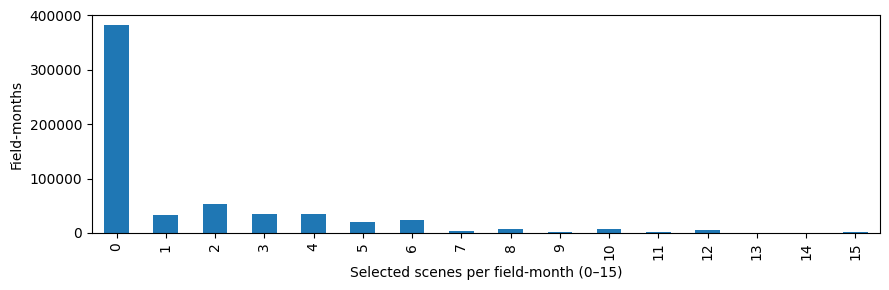

In [6]:
coverage_paths=[str(OUT/f"top15_dev_{s}/monthly_coverage.parquet") for s in SCHEMAS]
support=con.execute("""SELECT selected_scenes,count(*) field_months
FROM read_parquet(?) GROUP BY 1 ORDER BY 1""",[coverage_paths]).df()
ax=support.plot.bar(x="selected_scenes",y="field_months",legend=False,figsize=(9,3))
ax.set(xlabel="Selected scenes per field-month (0–15)",ylabel="Field-months")
plt.tight_layout(); plt.show()

## Outputs and limitations

The two top15_dev folders under data/clean contain candidate decisions, ranked top-15 scenes and full monthly coverage. The two top15_dev_features folders contain monthly feature summaries and provenance. The final top15_model_ready.parquet has one row per eligible development field. All data remain under the ignored data/ folder.

Most locations are GPS points, so SCL and cloud quality apply to a sampled pixel rather than a verified field boundary. Some planting dates are missing or unverified. Cloud probability is absent for many historic scenes; the score gives a missing value neutral credit rather than discarding the scene. Converted reflectance outside 0–1 is reported but does not silently replace or rerank a selected image. No locked row is scored by this notebook.